# Case study: a goal-based Strategic Asset Allocation with semi-liquid private-market funds (ELTIF)

**USD 100m multi-asset mandate · private markets through evergreen ELTIFs instead of closed-end funds**

This notebook solves **the same case** as [`Cases_study_SAA_ClosedEnd_PrivateMarkets.ipynb`](Cases_study_SAA_ClosedEnd_PrivateMarkets.ipynb), but implements private equity, private debt and infrastructure through **semi-liquid evergreen funds (ELTIF under the ELTIF 2.0 rules)** instead of closed-end funds. Sections 1–8 (client, data, assumptions, SAA) follow the closed-end notebook. From section 9 on, the vehicle changes everything: there is no pacing plan, no capital calls, no funding ladder and no recommitment, but there are redemption gates and a fee and cash drag. Every step
explains **what** is done, **why**, and **how to read the output**. It runs on the synthetic data in
`examples/data` (simulated prices and return assumptions, no real market data). The method is real;
the numbers only illustrate it.

---

## The illustrative mandate

The mandate is fictional and stylised. It stands for a common situation: a cash-heavy investor who
wants inflation-plus returns and stable income, and is considering private markets.

| | |
|---|---|
| **Objective** | A diversified multi-asset portfolio built on a systematic, policy-driven Strategic Asset Allocation (SAA) |
| **Horizon** | 10-year rolling, annualised |
| **Return goal** | US CPI + 3% a year |
| **Income goal** | 3.5% cash income by 2032 |
| **Risk goal** | 6–8% annualised volatility |
| **Eligible assets** | Liquidity · government bonds · IG and HY credit · listed equities · gold · infrastructure · private equity · private debt |
| **Current allocation** | 45% cash · 38% public debt · 15% public equities · 2% gold · no infrastructure or private assets |
| **Size** | USD 100m |

**What this notebook works out:** the open questions about the client, a target SAA with its
methodology, the transition from today's book, allocations within each asset class, and the
private-markets commitment pacing and liquidity plan.

## The solution at a glance

| Step | Question | Tool in `saa-pm` |
|---|---|---|
| 1 | What does the client want, and what don't we know? | (judgement) + the input files |
| 2 | Translate the mandate into model inputs | input folder → `load_mandate` |
| 2b | Do all input files arrive correctly? | `data_check.py`: reconciliation + fault injection |
| 2c | How is an ELTIF modelled? | semi-liquid sleeve: `liquid=True` + `redemption_limit` (gate) |
| 3 | Are private returns smoothed? | Geltner desmoothing |
| 4 | Expected return, income and risk per asset class | `StateBuilder` → CMAs + `RiskModel` |
| 5 | How far is today's book from the goals? | `GoalOptimizer.diagnose` |
| 6 | **Strategic target** | `GoalOptimizer` (return → income → risk) |
| 7 | Why this allocation? Is it robust? | frontiers, risk attribution, income, sensitivity |
| 8 | Allocations within each asset class | weights + ELTIF selection policy |
| 9 | **Subscription plan and transition** | quarterly rebalances (`PointInTimeAllocator.today_problem`) |
| 10 | **Liquidity management with gates** | liquidity tiers, gate run-off, denominator effect, withdrawal stress |
| 11 | What can go wrong, and what wealth outcomes to expect | stress tests, Monte Carlo |
| 12 | Closed-end vs semi-liquid | side-by-side comparison |
| 13 | Summary for the investment committee | |

> Run time: about 3 minutes (2 without the input stress test).

## 0. Setup

These cells import the library and set display options. If `saa_pm` is not installed, the notebook
falls back to the source folder of the repository. Two small helpers print tables as percentages or
in USD millions.

In [1]:
import os
import sys
import warnings

try:
    import saa_pm
except ImportError:  # running from a clone without `pip install -e .`
    sys.path.insert(0, os.path.abspath(os.path.join("..", "src")))
    import saa_pm

import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from saa_pm import (
    GoalOptimizer,
    PointInTimeAllocator,
    StateBuilder,
    load_mandate,
    validate,
)
from saa_pm.analytics import frontier, liquidity, risk, sensitivity, stress
from saa_pm.analytics.performance import performance_table
from saa_pm.analytics.wealth import simulate_wealth

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.5),
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

DATA = "data" if os.path.isdir("data") else os.path.join("examples", "data")
sys.path.insert(0, os.path.dirname(os.path.abspath(DATA)))  # examples/ -> data_check.py
from data_check import check_inputs, stress_test_inputs  # noqa: E402


def pct(df, d=1):
    # format every float as a percentage (for display only)
    return df.map(lambda x: f"{x:.{d}%}" if isinstance(x, (float, np.floating)) and pd.notna(x) else x)


def mio(df, d=1):
    # format every float in USD millions (for display only)
    return df.map(lambda x: f"{x / 1e6:,.{d}f}" if isinstance(x, (float, np.floating)) and pd.notna(x) else x)


print("saa_pm", saa_pm.__version__, "| data folder:", DATA)

saa_pm 1.1.0 | data folder: data


## 1. Client profile: what else would we need to know?

The mandate defines **goals** (return, income, risk) and **eligible assets**. It does not describe the
client. Before an investment committee signs off an SAA, we would ask for the following. Each item
lists the **assumption this notebook makes** in its place.

| # | Missing information | Why it matters | Assumption used here |
|---|---|---|---|
| 1 | **Type of investor and governance** (foundation, family office, pension, insurer?), decision process, delegated authority | Sets the regulatory frame, the risk capacity and how quickly the portfolio can be changed | A tax-exempt foundation-type investor with an investment committee that meets yearly |
| 2 | **Base currency and FX hedging policy** | Non-USD bonds are usually hedged and equities partly hedged; this changes risk and return | USD base. Return assumptions are read as USD (hedged where relevant). |
| 3 | **Purpose of the 3.5% income.** Is it paid out (spending rule) or reinvested? | A payout is a permanent outflow that must be funded even in bad years | Income is a *portfolio characteristic* (cash yield), not a fixed payout. No external flows. |
| 4 | **Definition of income** | Do private distributions count, or only coupons, dividends and yield? Return of capital is not income. | Expected cash yield per asset class (the `income` assumption) |
| 5 | **Contributions and withdrawals** (amounts, timing) | They drive liquidity and the commitment budget | None during the horizon |
| 6 | **Liquidity requirements**: minimum liquid share, maximum illiquid share, emergency needs | Sizes the private-markets programme | Illiquid ≤ 32% (policy group limit), with all known calls pre-funded |
| 7 | **Risk tolerance beyond volatility**: maximum drawdown, CVaR, probability of a real loss | Volatility alone understates tail risk and illiquid risk | Reported alongside volatility (stress tests, Monte Carlo) |
| 8 | **Which volatility is the 6–8% measured on?** | Reported private-market volatility is *smoothed* and too low | **Desmoothed** private-market volatility, plus an illiquidity risk charge |
| 9 | **Inflation measure and assumption** (CPI-U headline? which forecast?) | Sets the return goal | US CPI 3.25% → return goal **6.25%** |
| 10 | **Details of the current book**: duration and credit quality of the 38% public debt, embedded gains, lock-ups | Transition cost, tax and the risk of today's book | 30% US Treasuries + 8% US IG; 15% equities = 7% US dividend + 8% US Nasdaq |
| 11 | **Tax, regulatory, ESG and exclusion constraints** | Can rule out vehicles or sectors | None |
| 12 | **Implementation constraints**: vehicles (funds, ETFs, mandates), fee budget, minimum tickets, use of derivatives or leverage | USD 100m is small for direct private-fund commitments (USD 1–5m tickets) | Long-only, unlevered. Private markets through **semi-liquid ELTIFs** (this notebook). |
| 13 | **Benchmark, rebalancing and reporting** | How success is measured and how drift is managed | Policy portfolio = strategic target; annual review |
| 14 | **Existing manager relationships** | Speeds up private-markets access | None |

> **Takeaway:** the goals are clear but the *client* is not. Items 3, 6, 8 and 12 matter most for
> this mandate, because they decide how much illiquidity the portfolio can carry.

## 2. From the mandate to model inputs

`saa-pm` reads a mandate from a few small tables. We start from the repository's example data and
change only what the mandate specifies:

| File / frame | Role | Source in this notebook |
|---|---|---|
| `assets` | One row per asset class: expected return, income, liquidity, min/max weight, desmoothing flag, NAV frequency | Example data. Infrastructure is moved into **Real Assets**, as in the mandate. |
| `prices` | Month-end total-return index levels, used for the risk model | Example data (simulated, 2011–2026) |
| `groups` | Limits on groups of assets, e.g. equities 25–60% or private markets 6–32% | Example data. "Real Assets" = gold + infrastructure, 3–20%. |
| `holdings` | Today's portfolio in USD | **From the mandate:** 45% cash, 38% public debt, 15% equities, 2% gold |
| `config` | Goals and model settings | **From the mandate:** CPI + 3%, income 3.5% by 2032, 6–8% volatility |
| `pacing` | How each private programme calls and returns capital | Example data |
| `stress_*` | Factor history and stress scenarios | Example data |

**The asset universe.** The mandate's asset classes map to 24 model sleeves:

| Mandate | Model sleeves |
|---|---|
| Liquidity | Cash, US STR (T-bills) |
| Government bonds | US, UK, JP, EU Govt |
| IG / HY credit | US IG, EU IG, US HY, EU HY, EM hard currency |
| Listed equities | US (dividend, equal-weight, Nasdaq), EU ex UK, EU dividend, UK, Japan, Pacific ex Japan, EM |
| Real assets | Gold, Private Infrastructure |
| Private markets | Private Equity, Private Debt |

In [2]:
def rd(name, **kw):
    return pd.read_csv(os.path.join(DATA, f"{name}.csv"), **kw)


assets = rd("assets")
prices = rd("prices", index_col=0, parse_dates=True)
groups = rd("groups")
pacing = rd("pacing")
stress_factors = rd("stress_factors", index_col=0, parse_dates=True)
stress_scenarios = rd("stress_scenarios")

# the mandate classifies infrastructure as a REAL asset (with gold)
assets.loc[assets["name"] == "Priv Infra", "group"] = "Real Assets"
groups.loc[groups["name"] == "Real Assets", ["members", "lo", "hi"]] = ["Gold|Priv Infra", 0.03, 0.20]


assets[
    [
        "name",
        "group",
        "exp_return",
        "income",
        "liquid",
        "lb",
        "ub",
        "appraisal_based",
        "ladder_bucket",
        "nav_frequency",
    ]
]

,name,group,exp_return,income,liquid,lb,ub,appraisal_based,ladder_bucket,nav_frequency
0,Cash,Liquidity,0.0370,0.0370,True,0.0100,0.2800,False,1.0000,M
1,US STR,Liquidity,0.0380,0.0380,True,0.0000,0.2400,False,2.0000,M
2,US Govt,Rates,0.0470,0.0380,True,0.0300,0.2500,False,NaN,M
3,UK Govt,Rates,0.0455,0.0435,True,0.0000,0.0800,False,NaN,M
4,JP Govt,Rates,0.0340,0.0250,True,0.0000,0.0800,False,NaN,M
5,EU Govt,Rates,0.0500,0.0335,True,0.0000,0.1000,False,NaN,M
6,EM HC,Credit,0.0600,0.0600,True,0.0300,0.0800,False,NaN,M
7,US IG,Credit,0.0535,0.0545,True,0.0300,0.2200,False,3.0000,M
8,EU IG,Credit,0.0540,0.0365,True,0.0200,0.1000,False,NaN,M
9,EU HY,Credit,0.0510,0.0590,True,0.0000,0.0500,False,NaN,M


**Today's holdings.** The mandate gives only the asset-class split. We map it to model sleeves as
follows (assumption 10 in the client profile):

* 45% cash → `Cash`
* 38% public debt → 30% `US Govt` and 8% `US IG`
* 15% equities → 7% `US Dvd Eq` and 8% `US Nasdaq Eq`
* 2% gold → `Gold`

There are no private holdings and no undrawn commitments.

In [3]:
PV0 = 100_000_000
current_mv = {"Cash": 45e6, "US Govt": 30e6, "US IG": 8e6, "US Dvd Eq": 7e6, "US Nasdaq Eq": 8e6, "Gold": 2e6}

holdings = pd.DataFrame({"asset": assets["name"], "market_value": 0.0, "commitments_undrawn": 0.0})
holdings["market_value"] = holdings["asset"].map(current_mv).fillna(0.0)
assert holdings["market_value"].sum() == PV0
holdings[holdings["market_value"] > 0].assign(weight=lambda d: d["market_value"] / PV0)

,asset,market_value,commitments_undrawn,weight
0,Cash,"45,000,000.0000",0.0000,0.4500
2,US Govt,"30,000,000.0000",0.0000,0.3000
7,US IG,"8,000,000.0000",0.0000,0.0800
11,US Dvd Eq,"7,000,000.0000",0.0000,0.0700
13,US Nasdaq Eq,"8,000,000.0000",0.0000,0.0800
20,Gold,"2,000,000.0000",0.0000,0.0200


**Goals and settings.** The mandate's goals become configuration keys:

* **Return:** `cpi` 3.25% (our US CPI assumption) + `return_spread` 3% = **6.25%** a year.
* **Income:** `target_income` 3.5% by `income_target_year` 2032. The binding income floor glides
  linearly from today's 3.46% to 3.5% (the `income_glide_*` keys).
* **Risk:** `vol_lo` 6% and `vol_hi` 8%.

The goals are **ranked**: return first, then income, then the risk band. Among the portfolios that
meet the goals, the optimiser picks the one with the **lowest risk**. The other settings (risk model,
turnover cap, funding ladder) keep the example's values.

> **Fine print: inputs**
>
> * **Units.** All rates are annual decimals. A value above 1 in a rate field (e.g. `4.7`) is read
>   as a percent and reported (the data check flags it).
> * **Arithmetic vs geometric.** `exp_return` is the *arithmetic* expected return, which is what a
>   one-period optimiser needs. A portfolio compounds at roughly `μ − σ²/2`: at about 6.6% and 6%
>   volatility, about 6.4% a year. The goal "CPI + 3%" is applied to the arithmetic expected return.
>   Section 11.3 shows the compounded (geometric) outcome.
> * **The income glide path.** The binding income floor rises linearly from 3.46% (October 2026) to
>   3.50% in 2032. The final goal still applies; the glide only stops the optimiser from treating a
>   2032 goal as binding today. Every portfolio in this study exceeds the final 3.5% anyway, except
>   the current book and the first rebalance.
> * **Total-return prices.** `prices.csv` must hold *total-return* levels (income reinvested).
>   `validate` warns if a series looks like a price index (realised return ≈ assumption − income).
> * **Month-end clock.** Every date is moved to month-end. If two rows fall in the same month, only
>   the last one is used; the data check flags this.

In [4]:
config = dict(rd("config")[["key", "value"]].values)
config.update(
    cpi=0.0325,
    return_spread=0.03,  # return goal = CPI + 3%
    target_income=0.035,
    income_target_year=2032,  # income goal: 3.5% by 2032 ...
    income_glide_start_year=2026.75,
    income_glide_start_income=0.0346,  # ... from today's 3.46%
    vol_lo=0.06,
    vol_hi=0.08,  # risk band
)


CASE_DIR = os.path.join(tempfile.gettempdir(), "saa_pm_case_study")


def write_case(
    folder, assets_df, schedule=None, prices_df=None, holdings_df=None, pacing_df=None, groups_df=None
):
    # write the case as a normal input folder: exactly what `saa-pm run <folder>` would read
    os.makedirs(folder, exist_ok=True)
    for f in os.listdir(folder):
        if f.endswith(".csv"):
            os.remove(os.path.join(folder, f))
    (prices if prices_df is None else prices_df).rename_axis("date").to_csv(
        os.path.join(folder, "prices.csv")
    )
    stress_factors.rename_axis("date").to_csv(os.path.join(folder, "stress_factors.csv"))
    frames = {
        "assets": assets_df,
        "groups": groups if groups_df is None else groups_df,
        "pacing": pacing if pacing_df is None else pacing_df,
        "holdings": holdings if holdings_df is None else holdings_df,
        "stress_scenarios": stress_scenarios,
        "config": pd.DataFrame({"key": list(config), "value": list(config.values())}),
    }
    if schedule is not None and len(schedule):
        frames["commitment_future"] = schedule
    for name, df in frames.items():
        df.to_csv(os.path.join(folder, f"{name}.csv"), index=False)
    return folder


def build_mandate(assets_df, schedule=None, folder=CASE_DIR, **frames):
    # one place that turns the case into a MandateData bundle: write the folder, then load it
    return load_mandate(write_case(folder, assets_df, schedule, **frames))


pd.Series(config).loc[
    [
        "cpi",
        "return_spread",
        "target_income",
        "income_target_year",
        "vol_lo",
        "vol_hi",
        "turnover_limit",
        "halflife",
        "shrink",
        "uplift",
        "ladder_edge_1",
        "ladder_edge_2",
    ]
]

cpi                      0.0325
return_spread            0.0300
target_income            0.0350
income_target_year   2,032.0000
vol_lo                   0.0600
vol_hi                   0.0800
turnover_limit           0.3000
halflife                36.0000
shrink                   0.2500
uplift                   0.1500
ladder_edge_1            2.0000
ladder_edge_2            3.0000
dtype: float64

## 2c. The vehicle: semi-liquid ELTIF instead of closed-end funds

### What changes with an ELTIF?

The companion notebook uses **closed-end funds**: commit, wait for calls, receive distributions, and
**re-commit** every year to keep the allocation. A **semi-liquid evergreen ELTIF** (European
Long-Term Investment Fund under the ELTIF 2.0 rules, in force since January 2024) works differently:

| | Closed-end fund | Evergreen / semi-liquid ELTIF |
|---|---|---|
| **Entry** | Commitment, called over 2–4 years | **Subscription at NAV**, invested at once (monthly or quarterly dealing) |
| **Re-investment** | New commitments every year (pacing plan) | **None needed.** The fund recycles its own proceeds (and reinvests income in the accumulating share class). |
| **J-curve** | Yes: fees and calls before distributions | Largely avoided: you buy into a seasoned portfolio |
| **Liquidity for the investor** | None until distributions | **Redemptions** (e.g. quarterly with notice), subject to a **gate** |
| **Funding ladder** | Needed for unfunded commitments | **Not needed**: there are no calls |
| **Return** | Full private-market return | Lower: a **liquidity sleeve** of 10–20% sits in cash or liquid credit (cash drag), plus higher running fees |
| **Minimum ticket** | Often USD 1–5m per fund | Small: suits a USD 100m mandate, especially for PE |
| **Key risk** | Over-commitment, liquidity squeeze | **Gating** in stress (redemptions suspended or pro-rated), NAV smoothing, a liquidity mismatch inside the fund |

### How the ELTIF fits into the framework

`saa-pm` models it as a **semi-liquid** sleeve, using one optional column in `assets.csv`:

| Column | Closed-end sleeve | ELTIF sleeve |
|---|---|---|
| `liquid` | `False` (pinned at NAV, built through calls) | **`True`**: can be bought at NAV in any rebalance |
| `redemption_limit` | – | **Maximum share of the holding redeemable per rebalance** (the gate), e.g. `0.05` |
| `appraisal_based` | `True` | `True`: the NAV is appraisal-based, so it is still desmoothed |
| pacing row, `commitment_future` | needed | **not needed** |

The engine then treats the sleeve as follows:

* **Optimiser.** Buying is free. In every rebalance, selling is capped at `redemption_limit ×
  holding`, enforced by a constraint and checked in the audit (`redemption gates`).
* **Risk model.** The sleeve gets the same **illiquidity uplift** as a closed-end fund. Gated money
  is not liquid money.
* **Capital-call waterfall.** It is never used for forced sales: a gated fund cannot pay a call.
* **Liquidity profile.** It is reported as its own tier, `semi_liquid`.

### Modelling the ELTIF version of each sleeve

Each ELTIF holds `1 − c` in the private strategy and `c` in a liquidity sleeve (cash), and charges an
extra running fee `f` over the closed-end vehicle:

$$ \mu^{ELTIF} = (1-c)\,\mu^{PM} + c\,\mu^{cash} - f \qquad
r^{ELTIF}_q = (1-c)\, r^{PM}_q + c\, r^{cash}_q - f/4 $$

The return series is built quarterly from the private index and cash. It keeps the private index's
smoothing, so the desmoothing step applies as before. Choose the vehicle **per sleeve** in
`VEHICLE`. The defaults below are illustrative: a 15% liquidity sleeve, a 0.6% extra fee, and a
gate of 5% of the holding per quarter (the binding-gate case in a stress).

In [5]:
VEHICLE = {"Priv Debt": "eltif", "Priv Eq": "eltif", "Priv Infra": "eltif"}  # or "closed_end" per sleeve
ELTIF_CASH, ELTIF_FEE, ELTIF_GATE = 0.15, 0.006, 0.05


def eltif_inputs(vehicle, base_assets):
    # return (assets, prices, groups, pacing, holdings) with the chosen sleeves replaced by ELTIF versions
    a_df, p_df, g_df, pc_df = base_assets.copy(), prices.copy(), groups.copy(), pacing.copy()
    a_df["redemption_limit"] = np.nan
    cash_row = a_df.set_index("name").loc["Cash"]
    rename = {}
    for sleeve, kind in vehicle.items():
        if kind != "eltif":
            continue
        new = f"{sleeve} ELTIF"
        rename[sleeve] = new
        i = a_df.index[a_df["name"] == sleeve][0]
        r = a_df.loc[i]
        a_df.loc[
            i, ["name", "price_column", "liquid", "appraisal_based", "redemption_limit", "tx_cost_bps"]
        ] = [new, new, True, True, ELTIF_GATE, 25]
        a_df.loc[i, "exp_return"] = (
            (1 - ELTIF_CASH) * r["exp_return"] + ELTIF_CASH * cash_row["exp_return"] - ELTIF_FEE
        )
        a_df.loc[i, "income"] = (1 - ELTIF_CASH) * r["income"] + ELTIF_CASH * cash_row["income"] - ELTIF_FEE
        # quarterly NAV series: (1-c) x private index + c x cash - fee, on the private reporting dates
        lv = p_df[sleeve].dropna()
        cash_q = p_df["Cash"].reindex(lv.index)
        r_e = (1 - ELTIF_CASH) * lv.pct_change() + ELTIF_CASH * cash_q.pct_change() - ELTIF_FEE / 4
        p_df[new] = (lv.iloc[0] * (1 + r_e.fillna(0.0)).cumprod()).reindex(p_df.index)
        pc_df = pc_df[pc_df["asset"] != sleeve]
    for old, new in rename.items():
        g_df["members"] = (
            g_df["members"]
            .str.split("|")
            .map(lambda ms, old=old, new=new: "|".join(new if m == old else m for m in ms))
        )
    h_df = holdings.assign(asset=holdings["asset"].replace(rename))
    return a_df, p_df, g_df, pc_df, h_df


# keep the closed-end frames for the comparison, then switch the whole case to ELTIF vehicles
assets_ce, prices_ce, groups_ce, pacing_ce, holdings_ce = assets, prices, groups, pacing, holdings
assets, prices, groups, pacing, holdings = eltif_inputs(VEHICLE, assets_ce)
SLEEVE = {s: (f"{s} ELTIF" if VEHICLE[s] == "eltif" else s) for s in VEHICLE}  # closed-end name -> case name

# NO FUNDING LADDER: an ELTIF has no commitments and no capital calls, so there is nothing to pre-fund.
# The ladder buckets (Cash / T-bills / IG) and the ladder settings are removed from the case entirely.
assets["ladder_bucket"] = np.nan
for k in ("ladder_edge_1", "ladder_edge_2", "ladder_cover"):
    config.pop(k, None)
PRIVATE = list(SLEEVE.values())

data = build_mandate(assets)
print(data.universe, "| as of", data.asof.date(), f"| portfolio value USD {data.holdings.total:,.0f}")
print("semi-liquid (gated) sleeves:", data.universe.semi_liquid_names)
print("funding ladder buckets:", data.universe.ladder_map or "none - not needed without capital calls")
assets.loc[
    assets["name"].isin(PRIVATE),
    [
        "name",
        "group",
        "exp_return",
        "income",
        "liquid",
        "redemption_limit",
        "appraisal_based",
        "nav_frequency",
        "lb",
        "ub",
    ],
]

Universe(24 assets, 13 groups) | as of 2026-09-30 | portfolio value USD 100,000,000
semi-liquid (gated) sleeves: ['Priv Infra ELTIF', 'Priv Eq ELTIF', 'Priv Debt ELTIF']
funding ladder buckets: none - not needed without capital calls


,name,group,exp_return,income,liquid,redemption_limit,appraisal_based,nav_frequency,lb,ub
21,Priv Infra ELTIF,Real Assets,0.0879,0.0467,True,0.0500,True,Q,0.0200,0.1500
22,Priv Eq ELTIF,Private Markets,0.0960,0.0182,True,0.0500,True,Q,0.0000,0.1500
23,Priv Debt ELTIF,Private Markets,0.0667,0.0633,True,0.0500,True,Q,0.0200,0.1400


> **Fine print: the ELTIF construction**
>
> * **Same underlying, different wrapper.** The ELTIF series is the private index blended with cash,
>   so the *strategy* risk is the same as in the closed-end case. Only the wrapper differs: cash
>   drag, extra fee and liquidity terms.
> * **Fee drag hits income.** The extra fee is charged against income in the distributing share
>   class. With an accumulating class the sleeve pays no income, so the income goal would need other
>   sources.
> * **Gate on the holding.** `redemption_limit = 0.05` means at most 5% of *our ELTIF holding* per
>   rebalance (quarterly). This is the stressed case, in which the fund-level gate binds and
>   redemptions are pro-rated. In normal times a semi-liquid fund pays redemptions in full (within
>   its notice period).
> * **No funding ladder: a different liquidity approach.** In the closed-end case, liquidity
>   management is about cash going **out**: a ladder of cash, T-bills and IG pre-funds every known
>   capital call by due date. An ELTIF has no calls, so that machinery is switched off: no
>   `ladder_bucket`, no `commitment_future.csv`, no ladder floors in the optimiser. Cash and T-bills
>   are held only for their own return and risk. Liquidity management turns around and becomes
>   about cash that cannot get **back in**: gates, the denominator effect and withdrawals
>   (section 10).
> * **Bounds and groups carry over.** The ELTIF sleeves inherit the closed-end sleeves' bounds and
>   their membership in the groups (Private Markets ≤ 32%, Real Assets, Income assets). The policy
>   therefore limits illiquidity in the same way, whatever the wrapper.

## 2b. Data check: does every input file arrive correctly?

A mandate is fed by up to 13 CSV files: prices, assumptions, holdings, limits, pacing, call
schedules, histories and stress factors. One wrong cell can change the answer without any error
message. Examples: a return of `8.1` instead of `0.081`, a stale price feed, a level typed ×10, or a
private NAV booked in the wrong month. Before modelling, we therefore **prove** that the inputs
arrive in the model correctly. [`data_check.py`](data_check.py) has two tools:

**`check_inputs(folder)`** runs in four stages:

1. **Inventory.** Which files are present, their rows, columns and separator, and any unrecognised
   file names (a file named `flow.csv` would be silently ignored).
2. **Load and validate.** Reads the folder exactly as the study does (`load_mandate` + `validate`).
   Blocking problems become FAIL rows.
3. **Reconciliation.** Every raw value is compared with the value the model holds:
   * asset assumptions and bounds;
   * returns recomputed independently from the price levels;
   * holdings totals per position;
   * group limits and members;
   * every config key;
   * pacing parameters;
   * call schedules (rows and totals);
   * CMA, policy and flow histories.

   A dropped row, a remapped column or a percent read as a fraction shows up here.
4. **Plausibility checks the loader does not make:**
   * return outliers and *typo spikes* (a jump that reverses the next month);
   * stale prices, and blank months that are carried flat;
   * quarterly NAVs reported off the quarter calendar;
   * several rows in one month;
   * series that end early and pull the as-of date back;
   * unknown config keys (with a "did you mean");
   * scenarios that reference unknown factors;
   * calls outside the history;
   * incomplete CMA vintages.

Status levels: **FAIL** (must fix), **WARN** (check it), **INFO**, **PASS**.

The case inputs are written to a folder (`CASE_DIR`) and loaded from it, exactly like
`saa-pm run <folder>`. The check therefore sees exactly the files the model reads.

In [6]:
chk = check_inputs(CASE_DIR)
print(chk.text().splitlines()[0])
display(chk.summary())
chk.issues()

DATA CHECK: OK - 36 PASS, 12 INFO, 13 WARN, 0 FAIL


status,PASS,INFO,WARN,FAIL
file,,,,
(load),1,0,0,0
(validate),1,3,13,0
assets.csv,8,0,0,0
cma_history.csv,0,1,0,0
commitment_future.csv,0,1,0,0
commitments_actual.csv,0,1,0,0
config.csv,3,1,0,0
flows.csv,0,1,0,0
groups.csv,3,0,0,0


,file,check,status,detail
0,(validate),warning,WARN,current weight of 'Cash' 45.00% is outside [1....
1,(validate),warning,WARN,current weight of 'US Govt' 30.00% is outside ...
2,(validate),warning,WARN,current weight of 'EM HC' 0.00% is outside [3....
3,(validate),warning,WARN,current weight of 'EU IG' 0.00% is outside [2....
4,(validate),warning,WARN,current weight of 'EU ex UK Eq' 0.00% is outsi...
5,(validate),warning,WARN,current weight of 'EU Dvd Eq' 0.00% is outside...
6,(validate),warning,WARN,current weight of 'UK Eq' 0.00% is outside [2....
7,(validate),warning,WARN,current weight of 'JP Eq' 0.00% is outside [2....
8,(validate),warning,WARN,current weight of 'Pac ex JP Eq' 0.00% is outs...
9,(validate),warning,WARN,current weight of 'EM Eq' 0.00% is outside [3....


**Result:** no FAIL. The returns recomputed from the raw price levels match the model to machine
precision, and every asset, position, limit, config key and pacing row reconciles. The WARN rows are
the expected ones: today's book sits outside the policy bounds, which is what the transition fixes.
The INFO rows document defaults and the as-of date. The synthetic ELTIF price columns pass the same checks as any other series. The full table is in `chk.table`:

In [7]:
chk.table[chk.table["status"] == "PASS"].head(25)

,file,check,status,detail
0,assets.csv,file present,PASS,"24 rows x 14 columns, comma-separated"
1,prices.csv,file present,PASS,"190 rows x 28 columns, comma-separated"
2,holdings.csv,file present,PASS,"24 rows x 3 columns, comma-separated"
3,config.csv,file present,PASS,"21 rows x 2 columns, comma-separated"
4,groups.csv,file present,PASS,"13 rows x 4 columns, comma-separated"
5,pacing.csv,file present,PASS,"0 rows x 7 columns, comma-separated"
11,stress_factors.csv,file present,PASS,"189 rows x 6 columns, comma-separated"
12,stress_scenarios.csv,file present,PASS,"11 rows x 8 columns, comma-separated"
13,(load),folder loads,PASS,"Universe(24 assets, 13 groups), 189 months"
30,(validate),no blocking errors,PASS,13 warning(s)


### Stress test of the data pipeline (fault injection)

A check is only useful if it catches real mistakes. `stress_test_inputs` copies the clean example
data and then applies one change per case:

* **Format variants** must load an **identical model**: German locale (`;`, decimal comma,
  `dd.mm.yyyy`), percent strings, shuffled rows and columns, a UTF-8 BOM with Windows line endings,
  padded names, tab separators.
* **Injected faults** must be **caught** (FAIL) or at least **flagged** (WARN): typos in names,
  missing columns, text in numbers, duplicate dates, negative levels, returns instead of levels,
  inconsistent bounds, broken pacing, calls on liquid assets, negative amounts, contradictory
  goals, unknown keys or factors, a ×10 level typo, stale feeds, gaps, truncated series, off-calendar
  NAVs, two rows in one month, a percent unit error, a config-key typo and a mis-named file.

It runs about 30 cases and takes about a minute.

In [8]:
RUN_INPUT_STRESS_TEST = True

if RUN_INPUT_STRESS_TEST:
    st_inputs = stress_test_inputs(DATA)
    print(f"{(st_inputs['result'] == 'PASS').sum()}/{len(st_inputs)} cases behave as expected")
    with pd.option_context("display.max_colwidth", 95):
        display(st_inputs)

31/31 cases behave as expected


,case,kind,expected,result,observed
0,"German locale (';', decimal comma, dd.mm.yyyy)",variant,identical,PASS,identical model
1,percent strings in assets.csv ('4.7%'),variant,identical,PASS,identical model
2,rows and columns shuffled,variant,identical,PASS,identical model
3,UTF-8 BOM and Windows line endings,variant,identical,PASS,identical model
4,spaces around asset names,variant,identical,PASS,identical model
5,tab-separated prices.csv,variant,identical,PASS,identical model
6,typo in a holdings asset name,fault,caught,PASS,FAIL [(load)] ValueError: holdings.csv lists assets not in assets.csv: ['US Gov']
7,price column missing,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv has no column for ['US Dvd Eq']
8,text in a price cell,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv: non-numeric value in column 'US Dvd Eq' at 2013-06-30
9,duplicate date row,fault,caught,PASS,FAIL [(load)] ValueError: prices.csv: duplicate dates [Timestamp('2011-09-30 00:00:00')]


Every format variant loads the identical model, and every injected fault is caught or flagged with
a message that points to the file, the series and the date. **Silent** faults (stale feeds, gaps,
unit errors, typo spikes) are the dangerous ones, because the loader would accept them. The data
check exists for them.

> **Use it on your own data:** `python examples/data_check.py <folder>` (add `--stress` for the
> fault injection). It exits with code 1 on any FAIL, so it can gate an automated run.

## 3. Data quality, and why private-market volatility must be desmoothed

`validate` checks the inputs before anything is optimised. **Errors** would stop the study, for
example a missing price column or bounds that cannot add up to 100%. **Warnings** do not stop it.
Here they only say that today's book sits outside the policy bounds, which is exactly what the
transition will fix.

The most important line of the coverage table concerns the **private sleeves**. Their reported NAVs
are *appraisal-based*: valuers anchor on the last value, so returns are spread over several quarters.
This makes the series look far less risky than it really is. `saa-pm` **desmooths** them with the
Geltner (1993) filter, using the lag-1 autocorrelation φ of the series:

$$ r^{\text{true}}_t = \frac{r^{\text{obs}}_t - \varphi\, r^{\text{obs}}_{t-1}}{1-\varphi} $$

It does this on **quarterly** data (the private sleeves report quarterly; interpolating to monthly
would add fake autocorrelation), with φ capped at 0.6. An extra **illiquidity uplift** of 15% on
the volatility of the private sleeves then charges for the fact that they cannot be sold.

In [9]:
rep = validate(data)
print("blocking errors:", rep.errors or "none")
print(f"warnings: {len(rep.warnings)} (current book outside policy bounds - fixed by the transition)")
for w in rep.warnings[:3]:
    print("  !", w)

cov = rep.coverage.loc[PRIVATE, ["months", "realised_return", "vol_reported", "vol_desmoothed", "phi"]]
cov["hidden_vol"] = 1 - cov["vol_reported"] / cov["vol_desmoothed"]
pct(cov.drop(columns="months"), 1).assign(phi=cov["phi"].round(2))

blocking errors: none
warnings: 13 (current book outside policy bounds - fixed by the transition)
  ! current weight of 'Cash' 45.00% is outside [1.00%, 28.00%]
  ! current weight of 'US Govt' 30.00% is outside [3.00%, 25.00%]
  ! current weight of 'EM HC' 0.00% is outside [3.00%, 8.00%]


,realised_return,vol_reported,vol_desmoothed,phi,hidden_vol
asset,,,,,
Priv Debt ELTIF,6.6%,3.5%,5.6%,0.4300,37.0%
Priv Eq ELTIF,9.0%,13.9%,21.6%,0.4100,35.8%
Priv Infra ELTIF,8.7%,5.4%,8.4%,0.4100,35.8%


**How to read this:** a φ of about 0.4 means roughly 40% of each quarter's "true" move shows up only
in later quarters. The reported volatility understates the real one by about a third (`hidden_vol`).
An optimiser fed with reported volatilities would load up on private assets because they look
nearly riskless. Desmoothing prevents that.

> **Fine print: desmoothing**
>
> * **Frequency.** φ is estimated on **quarterly** returns, because the private NAVs are quarterly.
>   The monthly NAV series is carried flat between reports, so the quarter's return lands in the
>   reporting month. Interpolating would leak the next quarter's value into earlier months.
> * **Mean preserved, variance restored.** The filter leaves the average return (almost) unchanged
>   and scales the volatility by about `√((1+φ)/(1−φ))`. Because the *true* series is no longer
>   lagged, **correlations with listed markets rise** as well: private equity's correlation with
>   listed equity is about 0.7 after desmoothing.
> * **Cap.** φ is capped at 0.6 (at most a 2.5× scaling of returns) so that a noisy estimate cannot
>   explode the risk. `validate` warns when the cap binds.
> * **Two different φ values.** The coverage table estimates φ on the *full* history. The risk model
>   re-estimates φ inside its own window (at most 120 months, `max_lookback`), so its values (about
>   0.34–0.40) differ slightly. The risk model's values are the ones that count.
> * **First-order only.** Geltner removes lag-1 smoothing. NAVs smoothed over several quarters would
>   need a higher-order filter (Okunev–White). That is a known limitation, partly offset by the 15%
>   illiquidity uplift.

## 4. Capital market assumptions and the risk model

**Expected returns and income** (capital market assumptions, CMAs) are *inputs*. They come from
`assets.csv` and would normally be the house view. The tool shows the consequences of the
assumptions; it does not forecast them.

**Risk** is estimated from history, using only data available at the decision date:

1. Aggregate monthly returns to the **quarterly** frequency of the private sleeves.
2. **Desmooth** the private sleeves (step 3).
3. Exponentially weighted (EWMA) covariance with a 36-month half-life, so recent data counts more.
4. **Shrink** correlations 25% toward their average, which makes the optimiser less sensitive to estimation noise.
5. Add the 15% **illiquidity uplift** to the volatility of the private sleeves.
6. Repair to the nearest positive semi-definite matrix.

`StateBuilder(data).build()` assembles everything a decision at the last month may know:
assumptions, policy, goals, covariance and pacing parameters.

In [10]:
state = StateBuilder(data).build()
u, S = state.universe, state.sigma

cma = pd.DataFrame(
    {
        "class": [a.group for a in u],
        "exp_return": u.mu,
        "income": u.income,
        "vol": state.risk.vols.values,
        "min": u.lb,
        "max": u.ub,
        "liquid": u.liquid_mask,
    },
    index=u.names,
)
cma["return/vol"] = (cma["exp_return"] / cma["vol"]).round(2)
print(
    f"risk model: {state.risk.agg_months}-month returns, {state.risk.n_obs} observations, "
    f"effective sample {state.risk.n_eff:.0f}; Geltner phi:",
    {k: round(v, 2) for k, v in state.risk.phi.items()},
)
pct(cma, 2)

risk model: 3-month returns, 39 observations, effective sample 28; Geltner phi: {'Priv Infra ELTIF': 0.4, 'Priv Eq ELTIF': 0.33, 'Priv Debt ELTIF': 0.34}


,class,exp_return,income,vol,min,max,liquid,return/vol
Cash,Liquidity,3.70%,3.70%,0.57%,1.00%,28.00%,True,646.00%
US STR,Liquidity,3.80%,3.80%,1.34%,0.00%,24.00%,True,283.00%
US Govt,Rates,4.70%,3.80%,4.31%,3.00%,25.00%,True,109.00%
UK Govt,Rates,4.55%,4.35%,2.74%,0.00%,8.00%,True,166.00%
JP Govt,Rates,3.40%,2.50%,2.05%,0.00%,8.00%,True,166.00%
EU Govt,Rates,5.00%,3.35%,5.30%,0.00%,10.00%,True,94.00%
EM HC,Credit,6.00%,6.00%,8.54%,3.00%,8.00%,True,70.00%
US IG,Credit,5.35%,5.45%,6.75%,3.00%,22.00%,True,79.00%
EU IG,Credit,5.40%,3.65%,4.16%,2.00%,10.00%,True,130.00%
EU HY,Credit,5.10%,5.90%,6.94%,0.00%,5.00%,True,73.00%


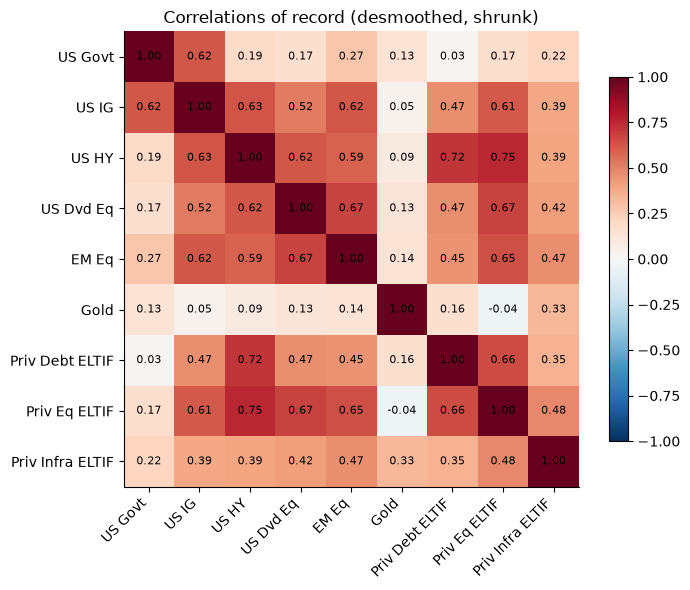

In [11]:
key = ["US Govt", "US IG", "US HY", "US Dvd Eq", "EM Eq", "Gold"] + PRIVATE
C = state.risk.correlation.loc[key, key]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(C.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(key)), key, rotation=45, ha="right")
ax.set_yticks(range(len(key)), key)
for i in range(len(key)):
    for j in range(len(key)):
        ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im, shrink=0.8)
ax.set_title("Correlations of record (desmoothed, shrunk)")
plt.tight_layout()
plt.show()

**What to notice:**

* **Private equity** is the riskiest sleeve once desmoothed (about 21% volatility in the ELTIF wrapper, 25% for the underlying). It is highly
  correlated with listed equities and high yield, so in risk terms it is mostly *equity beta*.
* **Private debt** has the best return per unit of risk among the growth assets, and the highest
  income (6.3% in the ELTIF after the cash drag and fee).
* **Infrastructure** combines a high return with moderate volatility and only moderate correlation
  to equities. It diversifies.
* **Gold** is almost uncorrelated with everything. It diversifies but pays no income.
* **Government bonds** have low correlation with equities and anchor the risk budget.

> **Fine print: risk model**
>
> * **Half-life.** 36 months becomes 12 quarters at the quarterly estimation frequency. The
>   covariance is annualised (×4) and bias-corrected for the uneven EWMA weights. The *effective*
>   sample (about 28 quarters) is much smaller than the nominal one, which is why shrinkage matters.
> * **Shrinkage.** A fixed 25% pull of every correlation toward the average correlation. Variances
>   are not changed.
> * **Illiquidity uplift.** Private (and gated ELTIF) volatilities ×1.15, so variances ×1.32.
>   Correlations stay the same. It is a *charge* for not being able to sell, not a statistical
>   estimate.
> * **Point in time.** The state is built from data up to the as-of date (2026-09-30). The
>   walk-forward backtest uses the same code at every past date, so there is no look-ahead.
> * **Cash volatility.** Cash shows about 0.6% volatility because its yield moved over the window. In
>   a one-period model this is a mild overstatement of cash risk.

## 5. Diagnosis of the current portfolio and feasibility of the goals

Two questions come before any optimisation:

1. **How far is today's book from the goals?**
2. **Are the goals attainable at all** with this universe and these limits? `diagnose()` computes the
   feasibility envelope *before* any target is imposed: maximum return, maximum income, minimum
   volatility, and the minimum volatility needed to reach the return goal.

In [12]:
goals = state.optimizer
w_cur = data.holdings.weights


def stats(w):
    w = np.asarray(w, float)
    return dict(
        exp_return=float(u.mu @ w),
        income=float(u.income @ w),
        vol=float(np.sqrt(w @ S.values @ w)),
        illiquid=float(w[[u.index(n) for n in PRIVATE]].sum()),
    )


print(
    f"goals: return >= {goals.target_return:.2%} | income >= {goals.target_income:.2%} today "
    f"(3.50% from 2032) | volatility {goals.vol_lo:.0%}-{goals.vol_hi:.0%}"
)
display(pct(pd.DataFrame({"current portfolio": stats(w_cur)}).T, 2))

diag = GoalOptimizer(u, S, goals).diagnose()
pd.Series(diag).to_frame("feasibility envelope")

goals: return >= 6.25% | income >= 3.46% today (3.50% from 2032) | volatility 6%-8%


,exp_return,income,vol,illiquid
current portfolio,4.97%,3.46%,3.34%,0.00%


,feasibility envelope
max_return,0.0795
max_income,0.0467
min_vol,0.0439
max_return_at_vol_hi,0.0739
max_income_at_vol_hi,0.0467
min_vol_for_return_target,0.0533
return_target_feasible,True
income_target_feasible,True


**Reading the diagnosis:**

* The current book earns about **5.0%** in expected terms, roughly 1.3% a year **short of CPI + 3%**.
  Its volatility (3.3%) is **below** the 6–8% band, so it carries too little risk to reach the goal.
* Its income (3.46%) already almost meets the goal, but only because **45% sits in cash and
  T-bills** at today's high short rates. That income is exposed to falling rates (reinvestment risk);
  it is not structural income.
* The goals **are attainable**. The return goal needs at least about 5.3% volatility (5.1% with closed-end funds, because the ELTIF
  drag lowers returns), below the 6–8% band, and the maximum income (about 4.7%) is above 3.5%. The band has room to spare.

## 6. The strategic target (SAA)

### 6.1 Methodology: a goal-ordered optimiser

A classic mean-variance optimiser trades return against risk with a single risk-aversion parameter
that a client cannot interpret. The mandate instead states **goals in priority order**, so the
optimiser follows them:

For each volatility level `v` on a grid across the band (6%, 6.17%, … 8%):

1. **Maximise expected return** subject to volatility ≤ `v` and all bounds and group limits.
2. **Without giving back return** (beyond a tiny tolerance), close any **income** shortfall.
3. Recover any return still left on the table.

Then it picks the **lowest-volatility grid point that meets both the return and the income goal**.
Risk is the *budget*, not the target: the client gets the goals at the least risk. If the goals were
unreachable inside the band, a documented fallback would apply, and the output would say so.

**Constraints:** fully invested, long-only, per-asset bounds (`lb`/`ub`), group limits (e.g. equities
25–60%, private markets 6–32%, sub-IG credit 5–15%, EM exposure 6–18%), and volatility ≤ the grid
point. All of it is convex, solved with `cvxpy`/Clarabel.

> **Fine print: optimiser**
>
> * **Grid.** The band is scanned at 13 volatility levels (`vol_steps`). If the goals are already met
>   at the band floor, the answer sits **exactly at 6.0%**. Being "too safe" is not allowed: the band
>   floor is a constraint (the client asked for 6–8%).
> * **Return tolerance.** Stage 2 (income) may give back at most `return_tol` = 0.001% of return.
>   The ordering is therefore strict, not a weighted compromise.
> * **Strategic vs rebalance mode.** The *strategic* solve has no turnover cap and no trading bands:
>   it is the destination. *Today's* solve (section 9) adds the turnover cap, the no-trade band for
>   private assets and, in the closed-end case, the funding-ladder floors (none here).
> * **Fallbacks.** If the goals cannot be met inside the band, a documented fallback applies
>   (maximum return, then minimum income gap). The rule is shown in `selection_rule` and in the
>   notes, never silently.
> * **Audit.** An independent numerical re-check of every constraint (the table further down). Use
>   it to prove to a reviewer that the solution respects the policy.

In [13]:
res_free = GoalOptimizer(u, S, goals).run()
w_free = pd.Series(res_free.weights, index=u.names)
print("rule:", res_free.solution.selection_rule)
display(pct(pd.DataFrame({"optimiser, no PE floor": stats(w_free)}).T, 2))
pct(w_free[PRIVATE].to_frame("weight"))

rule: return+income met in band -> min risk


,exp_return,income,vol,illiquid
"optimiser, no PE floor",6.69%,4.13%,6.00%,29.00%


,weight
Priv Debt ELTIF,14.0%
Priv Eq ELTIF,0.0%
Priv Infra ELTIF,15.0%


### 6.2 A policy decision: a strategic floor for private equity

Left alone, the optimiser holds **no private equity**. With 25% desmoothed volatility and high
correlation to listed equities, PE adds little that listed equities and high yield do not already
offer, *at these assumptions*. That is a legitimate result, but the mandate asks for a diversified
programme across private sub-strategies. There are also two reasons not to rely on a corner solution:

* **Estimation risk.** PE's desmoothed volatility rests on a short, appraisal-based history. A
  small change in φ moves it a lot.
* **Option value and lead time.** A private programme takes 4–5 years to build. Starting a small
  allocation now keeps the option to scale it up later.

So the investment committee sets a **3% minimum for private equity** (`PE_FLOOR`). The next cell
re-solves with that floor and shows what it costs. Set `PE_FLOOR = 0.0` to see the unconstrained
answer flow through the whole notebook.

In [14]:
PE_FLOOR = 0.03

assets_policy = assets.copy()
assets_policy.loc[assets_policy["name"] == SLEEVE["Priv Eq"], "lb"] = PE_FLOOR
data = build_mandate(assets_policy)
state = StateBuilder(data).build()
u, S, goals = state.universe, state.sigma, state.optimizer

res = GoalOptimizer(u, S, goals).run()
w_saa = pd.Series(res.weights, index=u.names)
sol = res.solution
print("rule:", sol.selection_rule)
cmp = pd.DataFrame(
    {"current": stats(w_cur), "SAA without PE floor": stats(w_free), "SAA (policy)": stats(w_saa)}
).T
display(pct(cmp, 2))
print(
    f"cost of the PE floor: {stats(w_free)['exp_return'] - stats(w_saa)['exp_return']:.2%} expected return "
    f"at the same {sol.vol:.1%} volatility"
)

rule: return+income met in band -> min risk


,exp_return,income,vol,illiquid
current,4.97%,3.46%,3.34%,0.00%
SAA without PE floor,6.69%,4.13%,6.00%,29.00%
SAA (policy),6.55%,4.00%,6.00%,30.09%


cost of the PE floor: 0.13% expected return at the same 6.0% volatility


The floor costs some expected return at equal risk, because the risk budget that PE uses is taken
from infrastructure. The policy SAA still clears the return goal with a margin. The audit confirms
that every constraint holds:

In [15]:
res.audit

,check,pass,value
0,budget sums to 1,True,0.99999999
1,single-asset bounds,True,ok
2,group bounds,True,ok
3,vol <= ceiling,True,6.0000%
4,vol >= band floor,True,6.0000%
5,income target,True,3.9961%
6,return target,True,6.5527%


,current,strategic,change
Liquidity,45.0%,7.7%,-37.3%
Rates,30.0%,21.2%,-8.8%
Credit,8.0%,12.0%,4.0%
Equities,15.0%,25.0%,10.0%
Real Assets,2.0%,17.2%,15.2%
Private Markets,0.0%,17.0%,17.0%


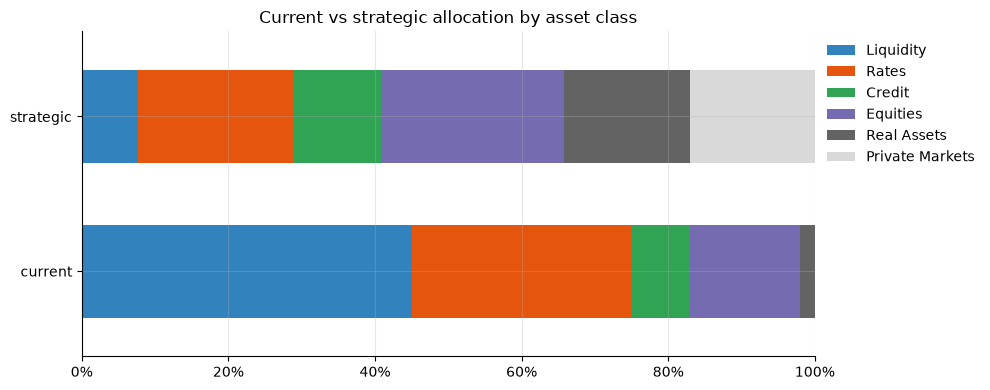

In [16]:
cls = pd.Series({a.name: a.group for a in u})
weights = pd.DataFrame({"current": pd.Series(w_cur, index=u.names), "strategic": w_saa})
by_class = (
    weights.groupby(cls)
    .sum()
    .loc[["Liquidity", "Rates", "Credit", "Equities", "Real Assets", "Private Markets"]]
)
display(pct(by_class.assign(change=by_class["strategic"] - by_class["current"])))

fig, ax = plt.subplots(figsize=(10, 4))
by_class.T.plot.barh(stacked=True, ax=ax, colormap="tab20c", width=0.6)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Current vs strategic allocation by asset class")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
plt.show()

### 6.3 The strategic target in words

| | Current | Strategic | Why |
|---|---|---|---|
| **Liquidity** | 45% | ≈ 8% | Cash is the drag on return. No capital calls to pre-fund, so far less cash is kept than in the closed-end case (17%). |
| **Rates** | 30% | ≈ 21% | Smaller, but split between US Treasuries and UK gilts. The equity hedge stays. |
| **Credit** | 8% | 12% | IG plus a sub-IG sleeve (HY, EM hard currency) for income |
| **Equities** | 15% | 25% | Global instead of US-only, at the 25% policy minimum |
| **Real assets** | 2% | ≈ 17% | Gold, plus infrastructure ELTIF at about 13% (inflation-linked cash flows) |
| **Private markets** | 0% | 17% | Private debt ELTIF at its 14% cap (income engine) plus 3% PE ELTIF |

The full asset-level target:

In [17]:
tgt = pd.DataFrame({"class": cls, "current": w_cur, "strategic": w_saa})
tgt = tgt[(tgt["current"] > 1e-4) | (tgt["strategic"] > 1e-4)]
pct(tgt.assign(change=tgt["strategic"] - tgt["current"]))

,class,current,strategic,change
Cash,Liquidity,45.0%,7.7%,-37.3%
US Govt,Rates,30.0%,13.2%,-16.8%
UK Govt,Rates,0.0%,8.0%,8.0%
EM HC,Credit,0.0%,3.0%,3.0%
US IG,Credit,8.0%,3.0%,-5.0%
EU IG,Credit,0.0%,4.0%,4.0%
US HY,Credit,0.0%,2.0%,2.0%
US Dvd Eq,Equities,7.0%,10.0%,3.0%
US Nasdaq Eq,Equities,8.0%,0.0%,-8.0%
EU ex UK Eq,Equities,0.0%,2.0%,2.0%


## 7. Why this allocation, and how robust is it?

### 7.1 What private markets add: efficient frontiers

`reference_frontiers` traces the maximum expected return at each volatility for three universes:

* **policy**: all limits, private sleeves allowed;
* **no privates**: the same limits, with the private sleeves set to zero;
* **unconstrained**: long-only and fully invested only.

The vertical gap between *policy* and *no privates* is **what private markets add at equal risk**.
The gap to *unconstrained* is **the cost of the policy limits**.

,policy,no_privates,unconstrained,privates_add,policy_cost
vol,,,,,
0.0600,6.55%,6.14%,7.68%,0.41%,1.13%
0.0700,7.03%,6.50%,8.14%,0.53%,1.11%
0.0800,7.37%,6.80%,8.51%,0.57%,1.14%


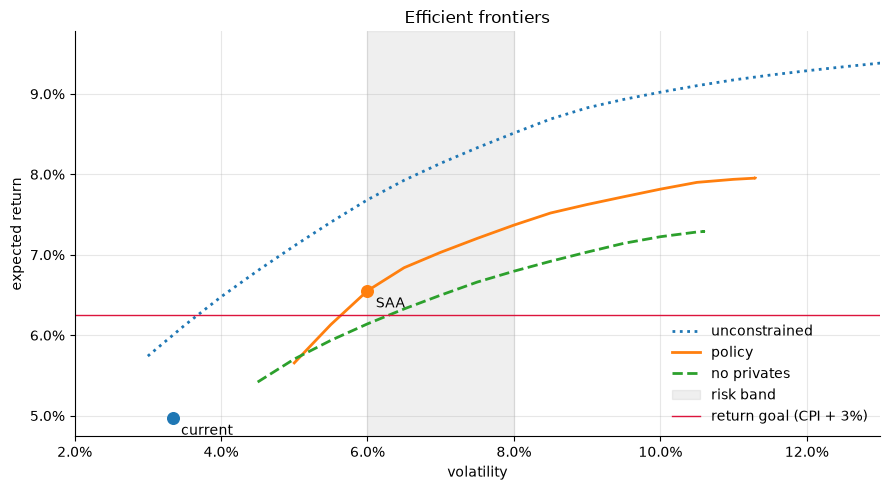

In [18]:
fronts = frontier.reference_frontiers(u, S, config=goals)
# ELTIF sleeves are liquid=True, so build the 'no privates' frontier explicitly
u_np = u.updated({n: {"lb": 0.0, "ub": 0.0} for n in PRIVATE})
u_np = u_np.with_groups(
    [g if not set(g.members) <= set(PRIVATE) else type(g)(g.name, g.members, 0.0, g.hi) for g in u_np.groups]
)
fronts["no_privates"] = frontier.frontier(u_np, S, list(np.linspace(0.03, 0.15, 25)), goals)
gaps = frontier.frontier_gaps(fronts, [0.06, 0.07, 0.08])
display(pct(gaps, 2))

fig, ax = plt.subplots(figsize=(9, 5))
for k, style in (("unconstrained", ":"), ("policy", "-"), ("no_privates", "--")):
    f = fronts[k]
    ax.plot(f["vol"], f["exp_return"], style, lw=2, label=k.replace("_", " "))
ax.axvspan(goals.vol_lo, goals.vol_hi, color="grey", alpha=0.12, label="risk band")
ax.axhline(goals.target_return, color="crimson", lw=1, label="return goal (CPI + 3%)")
for name, w in (("current", w_cur), ("SAA", w_saa.values)):
    s = stats(w)
    ax.scatter(s["vol"], s["exp_return"], s=70, zorder=5)
    ax.annotate(name, (s["vol"], s["exp_return"]), xytext=(6, -12), textcoords="offset points")
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("volatility")
ax.set_ylabel("expected return")
ax.set_xlim(0.02, 0.13)
ax.set_title("Efficient frontiers")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Without private markets, the best policy portfolio at 6% volatility **falls short** of the return
goal (about 6.1% against 6.25%). With ELTIFs, the same risk earns roughly 0.4% to 0.6% a year more
(0.6% to 0.9% with closed-end funds: the ELTIF wrapper costs part of the premium),
depending on the risk level. That is the case for building a private programme despite its illiquidity.

### 7.2 Where the risk comes from

Capital weights are misleading. 25% in equities produces about half of the portfolio's risk.
`risk.attribution` splits volatility into contributions that sum to 100%.

In [19]:
ports = {"current": w_cur, "strategic": w_saa.values}
att = risk.attribution(ports, S, u)
by = risk.attribution_by(att, u).pivot(
    index="asset_class", columns="portfolio", values=["weight", "pct_of_risk"]
)
display(pct(by))
pct(
    risk.concentration(ports, S, u)[
        [
            "vol",
            "diversification_ratio",
            "effective_n_weight",
            "effective_n_risk",
            "largest_risk",
            "largest_risk_share",
        ]
    ],
    2,
)

weight           pct_of_risk          
portfolio       current strategic     current strategic
asset_class                                            
Credit             8.0%     12.0%       13.3%      9.8%
Equities          15.0%     25.0%       57.3%     51.9%
Liquidity         45.0%      7.7%        3.4%      0.3%
Private Markets    0.0%     17.0%        0.0%     17.1%
Rates             30.0%     21.2%       24.8%      4.5%
Real Assets        2.0%     17.2%        1.1%     16.4%

,vol,diversification_ratio,effective_n_weight,effective_n_risk,largest_risk,largest_risk_share
current,3.34%,139.29%,321.96%,378.41%,US Nasdaq Eq,38.54%
strategic,6.00%,143.48%,1143.90%,1106.79%,US Dvd Eq,16.48%


The strategic portfolio spreads risk across about **11 effective positions instead of 4**, and no
single sleeve contributes more than about a sixth of the risk. The current book is dominated by the
US Nasdaq sleeve, which carries close to 40% of its (small) risk.

### 7.3 Income: does the SAA meet 3.5% by 2032, and from which sources?

In [20]:
W = pd.DataFrame(ports, index=u.names).T
pct(liquidity.income_decomposition(W, u, 0.035), 2)

,Credit,Equities,Liquidity,Private Markets,Rates,Real Assets,total,target,gap
current,0.44%,0.22%,1.66%,0.00%,1.14%,0.00%,3.46%,3.50%,-0.04%
strategic,0.63%,0.68%,0.28%,0.94%,0.85%,0.61%,4.00%,3.50%,0.50%


The SAA yields about **4.0%**, above the 3.5% goal. More importantly, the income moves
from cash (which reprices as soon as short rates fall) to **structural** sources: private debt,
credit, infrastructure and dividend equities.

### 7.4 Sensitivity: what if the assumptions are wrong?

`sensitivity.sensitivity` re-solves the strategic problem under shifted assumptions: return
assumptions ±1% per asset class, covariance ×0.8/×1.2, goals ±0.5%, risk band ±1%. A robust SAA
should keep meeting the goals with modest turnover. `binding_constraints` lists the limits that are
active at the optimum. These are the limits worth discussing first, because they shape the answer.

In [21]:
summ, _ = sensitivity.sensitivity(u, S, goals)
display(pct(summ[["exp_return", "income", "vol", "turnover"]], 2).assign(largest_move=summ["largest_move"]))
sensitivity.binding_constraints(w_saa.values, u)

,exp_return,income,vol,turnover,largest_move
case,,,,,
base,6.55%,4.00%,6.00%,0.00%,
CMA Credit +1.0%,6.70%,3.97%,6.00%,6.13%,EU IG +6.0%
CMA Credit -1.0%,6.43%,4.00%,6.00%,0.00%,US Govt -0.0%
CMA Equities +1.0%,6.80%,4.00%,6.00%,0.00%,Cash +0.0%
CMA Equities -1.0%,6.30%,4.00%,6.00%,0.00%,US Govt -0.0%
CMA Liquidity +1.0%,6.72%,4.02%,6.00%,14.23%,Cash +12.0%
CMA Liquidity -1.0%,6.53%,3.95%,6.00%,7.43%,US Govt +6.5%
CMA Private Markets +1.0%,6.72%,4.00%,6.00%,0.00%,US Govt -0.0%
CMA Private Markets -1.0%,6.41%,3.78%,6.00%,9.46%,Priv Debt ELTIF -7.7%


,constraint,side,limit,value
0,asset UK Govt,upper,0.0800,0.0800
1,asset EM HC,lower,0.0300,0.0300
2,asset US IG,lower,0.0300,0.0300
3,asset EU ex UK Eq,lower,0.0200,0.0200
4,asset EU Dvd Eq,lower,0.0200,0.0200
5,asset UK Eq,lower,0.0200,0.0200
6,asset Pac ex JP Eq,lower,0.0100,0.0100
7,asset EM Eq,lower,0.0300,0.0300
8,asset Priv Eq ELTIF,lower,0.0300,0.0300
9,asset Priv Debt ELTIF,upper,0.1400,0.1400


**Reading the sensitivity:** across every case the return and income goals are still met (rule
unchanged). Most cases need less than 10% turnover. The largest swings come from the **cash and
rates assumptions**: shifting cash or bond assumptions by 1% moves 7–14% between cash and Treasuries.
Private-market allocations are sticky, which is good, because they cannot be changed quickly.

The **binding** constraints show that the SAA leans on *diversification floors* (minimum weights in
EM, non-US equities, gold, credit) and on the **private debt cap**. The investment committee should
consciously confirm these limits, because they shape the answer as much as the assumptions do.

## 8. Implementation framework: allocations within each asset class

The optimiser decides the **public** sleeves directly. For the **private** sleeves the data has one
index per sleeve, so the split into sub-strategies is a **policy decision** (manager and vintage
diversification, J-curve management), not an optimisation output. The private splits below are the
proposed implementation policy.

In [22]:
pub = pd.DataFrame({"class": cls, "weight": w_saa})
pub = pub[(~pub.index.isin(u.illiquid_names)) & (pub["weight"] > 1e-4)]
pub["share_of_class"] = pub["weight"] / pub.groupby("class")["weight"].transform("sum")
pct(pub.sort_values(["class", "weight"], ascending=[True, False]))

,class,weight,share_of_class
EU IG,Credit,4.0%,33.3%
EM HC,Credit,3.0%,25.0%
US IG,Credit,3.0%,25.0%
US HY,Credit,2.0%,16.7%
US Dvd Eq,Equities,10.0%,40.0%
JP Eq,Equities,5.0%,20.0%
EM Eq,Equities,3.0%,12.0%
UK Eq,Equities,2.0%,8.0%
EU ex UK Eq,Equities,2.0%,8.0%
EU Dvd Eq,Equities,2.0%,8.0%


In [23]:
sub_policy = {
    SLEEVE["Priv Debt"]: {
        "Direct lending (senior, sponsor-backed)": 0.60,
        "Syndicated / broadly syndicated loans": 0.20,
        "Opportunistic & special situations credit": 0.20,
    },
    SLEEVE["Priv Eq"]: {
        "Buyout (small/mid)": 0.45,
        "Secondaries": 0.30,
        "Growth equity": 0.15,
        "Venture": 0.10,
    },
    SLEEVE["Priv Infra"]: {"Core": 0.50, "Core-plus": 0.35, "Value-add": 0.15},
}
rows = []
for sleeve, split in sub_policy.items():
    for sub, share in split.items():
        rows.append(
            dict(
                sleeve=sleeve,
                sub_strategy=sub,
                share_of_sleeve=share,
                portfolio_weight=share * w_saa[sleeve],
                usd_at_target=share * w_saa[sleeve] * PV0,
            )
        )
sub = pd.DataFrame(rows).set_index(["sleeve", "sub_strategy"])
sub.assign(
    share_of_sleeve=pct(sub[["share_of_sleeve"]])["share_of_sleeve"],
    portfolio_weight=pct(sub[["portfolio_weight"]], 2)["portfolio_weight"],
    usd_at_target=mio(sub[["usd_at_target"]])["usd_at_target"],
)

share_of_sleeve portfolio_weight usd_at_target
sleeve           sub_strategy                                                                            
Priv Debt ELTIF  Direct lending (senior, sponsor-backed)             60.0%            8.40%           8.4
                 Syndicated / broadly syndicated loans               20.0%            2.80%           2.8
                 Opportunistic & special situations credit           20.0%            2.80%           2.8
Priv Eq ELTIF    Buyout (small/mid)                                  45.0%            1.35%           1.3
                 Secondaries                                         30.0%            0.90%           0.9
                 Growth equity                                       15.0%            0.45%           0.4
                 Venture                                             10.0%            0.30%           0.3
Priv Infra ELTIF Core                                                50.0%            6.55%           6.5
                 Core-plus                                           35.0%            4.58%           4.6
                 Value-add                                           15.0%            1.96%           2.0

**Rationale: what to look for in each ELTIF.** With evergreen funds you do not build the
sub-strategy mix from many funds. You **select ELTIFs whose portfolios match the target mix**, and
you can split a sleeve across 2–3 ELTIFs for manager diversification.

* **Private debt ELTIF (income engine).** Mostly *senior direct lending*, plus a share of liquid
  syndicated loans: these form the fund's own liquidity sleeve and make redemptions possible. Check
  the distributing share class, the floating-rate share and the default and recovery track record.
* **Private equity ELTIF.** A **secondaries-led** or multi-strategy evergreen fund (buyout,
  secondaries, co-investments). This is where the vehicle helps most: USD 3m buys a diversified,
  seasoned portfolio with no J-curve.
* **Infrastructure ELTIF.** Core and core-plus (contracted, inflation-linked cash flows) fit the
  income goal and the gate, because stable assets are easier to value and refinance.
* **Public debt and equities** are as in the closed-end case. The liquid book no longer has to
  pre-fund capital calls.

## 9. Subscription plan and transition

### 9.1 How the ELTIF changes the transition

With closed-end funds, the private sleeves start at 0% and can only grow through capital calls over
about 5 years. **ELTIFs are bought at NAV.** They take part in the rebalance like any liquid asset,
and only three things limit the speed:

* the mandate's **turnover cap** (30% one-way per rebalance);
* the ELTIF's **dealing frequency** (monthly or quarterly subscriptions, possibly with a short
  queue in popular funds);
* our own **timing discipline** (tranches, as for equities).

We roll *today's* problem forward **one quarter at a time**. Each quarter starts from the previous
quarter's weights and re-solves with the same goals, bounds, groups and turnover cap, until the
portfolio stops moving. There are no capital calls, so no ladder floors apply. Market assumptions
stay frozen and only the book moves, exactly as in the closed-end projection.

In [24]:
alloc = PointInTimeAllocator(data)
w, steps, wts = data.holdings.weights, [], {}
dates_q = [asof_q for asof_q in pd.date_range(data.asof, periods=9, freq="QE")]
for q in range(8):
    r = alloc.today_problem(state, w_prev=w).solve()
    turnover = 0.5 * float(np.abs(r.weights - w).sum())
    wts[dates_q[q]] = r.weights
    steps.append(
        dict(
            date=f"{dates_q[q]:%Y-%m}",
            quarter=f"Q{q}",
            exp_return=r.solution.exp_return,
            income=r.solution.income,
            vol=r.solution.vol,
            private=float(r.weights[[u.index(n) for n in PRIVATE]].sum()),
            turnover=turnover,
            goals_met=r.solution.selection_rule.startswith("return+income met"),
            rule=r.solution.selection_rule,
        )
    )
    if turnover < 1e-3:
        break
    w = r.weights
path = pd.DataFrame(steps).set_index("date")
W_path = pd.DataFrame(wts, index=u.names).T
first_met = path.index[path["goals_met"]][0] if path["goals_met"].any() else "never"
display(pct(path[["exp_return", "income", "vol", "private", "turnover"]], 2).join(path[["goals_met"]]))
print("goals first met:", first_met, "| strategic SAA:", {k: f"{v:.2%}" for k, v in stats(w_saa).items()})

,exp_return,income,vol,private,turnover,goals_met
date,,,,,,
2026-09,6.11%,3.41%,6.50%,7.32%,30.00%,False
2026-12,6.50%,3.98%,6.00%,29.16%,30.00%,True
2027-03,6.55%,4.00%,6.00%,30.09%,10.15%,True
2027-06,6.55%,4.00%,6.00%,30.09%,0.00%,True


goals first met: 2026-12 | strategic SAA: {'exp_return': '6.55%', 'income': '4.00%', 'vol': '6.00%', 'illiquid': '30.09%'}


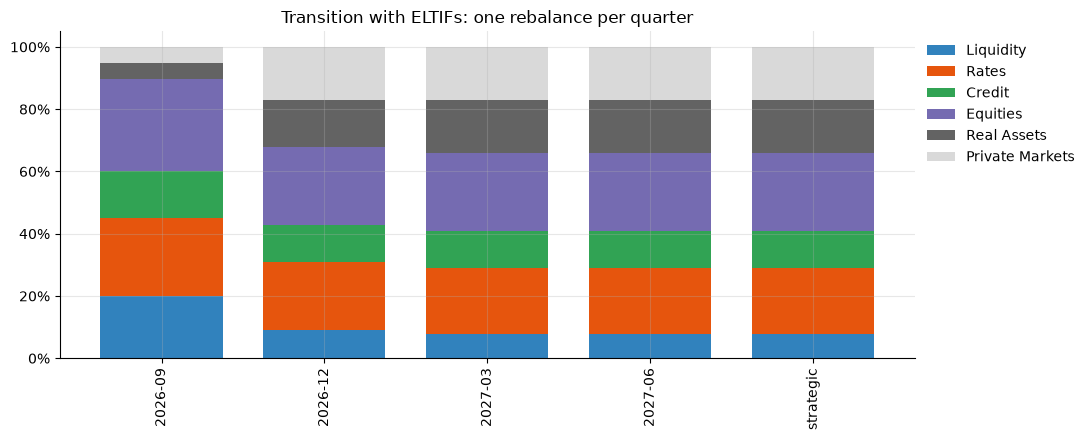

In [25]:
classes = ["Liquidity", "Rates", "Credit", "Equities", "Real Assets", "Private Markets"]
wclass = W_path.T.groupby(cls).sum().T.reindex(columns=classes)
wclass.index = [f"{d:%Y-%m}" for d in wclass.index]
wclass.loc["strategic"] = w_saa.groupby(cls).sum().reindex(classes)
fig, ax = plt.subplots(figsize=(11, 4.5))
wclass.plot.bar(stacked=True, ax=ax, colormap="tab20c", width=0.75)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Transition with ELTIFs: one rebalance per quarter")
ax.legend(bbox_to_anchor=(1, 1), frameon=False)
plt.tight_layout()
plt.show()

### 9.2 The subscription plan in USD

Subscriptions (+) and redemptions (−) per ELTIF and quarter, valued at the initial USD 100m. These
are the orders to place, instead of a commitment plan:

In [26]:
prev = pd.Series(data.holdings.weights, index=u.names)
orders = {}
for d, row in W_path.iterrows():
    orders[f"{d:%Y-%m}"] = (row - prev)[PRIVATE] * PV0
    prev = row
orders = pd.DataFrame(orders)
orders["total"] = orders.sum(axis=1)
display(mio(orders))
liquid_trades = (W_path.iloc[0] - pd.Series(data.holdings.weights, index=u.names)) * PV0
print("first-quarter trades in the liquid book (USD m):")
mio(liquid_trades[liquid_trades.abs() > 1e5].to_frame("trade"), 2).T

,2026-09,2026-12,2027-03,2027-06,total
Priv Debt ELTIF,2.0,12.0,0.0,0.0,14.0
Priv Eq ELTIF,3.3,-0.2,-0.2,-0.0,3.0
Priv Infra ELTIF,2.0,10.0,1.1,0.0,13.1


first-quarter trades in the liquid book (USD m):


,Cash,US Govt,EM HC,EU IG,US HY,US Nasdaq Eq,EU ex UK Eq,EU Dvd Eq,UK Eq,JP Eq,Pac ex JP Eq,EM Eq,Gold,Priv Infra ELTIF,Priv Eq ELTIF,Priv Debt ELTIF
trade,-25.00,-5.00,3.00,2.00,2.00,2.68,2.00,2.00,2.00,2.00,1.00,3.00,1.00,2.00,3.32,2.00


**Reading the transition:**

* The private sleeves are built in the **first one or two rebalances**. The 30% turnover cap
  decides how fast, not the funds. With closed-end funds the same weights take about five years.
* The goals are met as soon as the portfolio has rotated out of cash, and the path then sits on the
  strategic target. Cash is no longer needed as a ladder for capital calls.
* There is **no commitment risk**: no over-commitment (too much NAV later), no under-commitment
  (cash drag for years), and no recommitment every year.

> **Fine print: the subscription path**
>
> * **Capacity.** Popular ELTIFs may queue subscriptions or accept only monthly or quarterly
>   dealing. Spreading the private build over 2–4 quarters is a sensible default anyway.
> * **Entry costs.** The 25 bp `tx_cost_bps` stands for entry or anti-dilution fees. Some funds
>   charge more in the first year (an early-redemption fee). Check the prospectus.
> * **No J-curve, but you pay NAV.** You buy into a seasoned portfolio at its appraisal-based NAV.
>   If the NAV lags the market (smoothing), you may buy above fair value after a sell-off, or below
>   it after a rally.
> * **The quarterly roll** uses the same constraint set as every other solve: bounds, groups, the
>   turnover cap and, for ELTIFs, the **redemption gate** on any sale.

## 10. Liquidity management with gates

With closed-end funds the liquidity risk is the **capital call** (cash going *out* on the
manager's schedule). With ELTIFs there are no calls. The liquidity risk is the **gate**: in a stress
you may not get *your* money out when you need it. Four views follow.

### 10.1 Liquidity tiers along the path

`liquidity_profile` separates **liquid** assets, **semi-liquid** (gated ELTIF) assets and
**illiquid** (closed-end) assets. There is **no funding ladder** in this approach, because there are
no capital calls to pre-fund. The liquid tier is simply what can be sold within a month.

In [27]:
lp = liquidity.liquidity_profile(
    pd.concat([W_path.rename(index=lambda d: f"{d:%Y-%m}"), pd.DataFrame({"strategic": w_saa}).T]), u
)
pct(lp[["other_liquid", "semi_liquid", "illiquid"]].rename(columns={"other_liquid": "liquid"}), 1)

,liquid,semi_liquid,illiquid
2026-09,92.7%,7.3%,0.0%
2026-12,70.8%,29.2%,0.0%
2027-03,69.9%,30.1%,0.0%
2027-06,69.9%,30.1%,0.0%
strategic,69.9%,30.1%,0.0%


### 10.2 Gate run-off: how fast can the ELTIFs be turned into cash?

If the gate binds (5% of the holding per quarter), each quarter only 5% of the *remaining* holding
is paid out:

In [28]:
held = float(w_saa[PRIVATE].sum())
q = np.arange(0, 13)
gate_path = pd.DataFrame(
    {
        "ELTIF weight left": held * (1 - ELTIF_GATE) ** q,
        "cumulative cash raised": held * (1 - (1 - ELTIF_GATE) ** q),
    },
    index=pd.Index(q, name="quarters"),
)
pct(gate_path.loc[[0, 1, 2, 4, 8, 12]], 1)

,ELTIF weight left,cumulative cash raised
quarters,,
0,30.1%,0.0%
1,28.6%,1.5%
2,27.2%,2.9%
4,24.5%,5.6%
8,20.0%,10.1%
12,16.3%,13.8%


With a binding gate, only about 40% of the position can be redeemed in **three years**. In a stress,
an ELTIF is **nearly as illiquid as a closed-end fund**. Its advantage is on the way *in*, not on the
way *out*. The illiquidity cap of the policy (Private Markets ≤ 32%) therefore applies unchanged.

### 10.3 The denominator effect: a market crash pushes the gated share above its cap

Listed assets reprice at once, while appraisal-based NAVs lag. After a crash the *share* of the
private sleeves jumps, and with a gate it cannot be sold back down quickly. We apply a severe
scenario, **equities −30%** (three times the `Equities −10%` factor shock), to the strategic
portfolio. Every asset moves through its estimated (desmoothed) beta. The ELTIF NAVs, however, are
**reported** with the Geltner lag: only `(1 − φ)` of the true move shows up in the crash quarter, and
the rest arrives in later quarters. Then we count how many quarters of gated
redemptions it takes to get back under the cap. In the meantime the liquid book is rebalanced around
the gated sleeves.

In [29]:
fs = stress.FactorStress(u, data.common_returns, data.stress_factors)
shock = stress.scenario_shocks(data.stress_scenarios, data.stress_factors)["Equities -10%"]
moves = fs.asset_moves({k: 3 * v for k, v in shock.items()})  # true (desmoothed) moves
phi = pd.Series(state.risk.phi).reindex(u.names).fillna(0.0)
moves_reported = moves * (1 - phi)  # appraisal NAVs show only (1 - phi) of the move in the crash quarter
cap = next(g.hi for g in u.groups if g.name == "Private Markets")
priv_members = [m for g in u.groups if g.name == "Private Markets" for m in g.members]
w0 = w_saa.copy()
w1 = w0 * (1 + moves_reported)
pv1 = w1.sum()
w1 = w1 / pv1
share = float(w1[priv_members].sum())
qs, s_q = 0, share
while s_q > cap + 1e-9 and qs < 40:
    qs += 1
    s_q = share * (1 - ELTIF_GATE) ** qs / (1 - share + share * (1 - ELTIF_GATE) ** qs)
crash = pd.Series(
    {
        "portfolio return in the crash (reported)": pv1 - 1,
        "ELTIF NAV move (reported)": float((w0[PRIVATE] * moves_reported[PRIVATE]).sum() / w0[PRIVATE].sum()),
        "ELTIF true move (desmoothed)": float((w0[PRIVATE] * moves[PRIVATE]).sum() / w0[PRIVATE].sum()),
        "Private Markets share before": float(w0[priv_members].sum()),
        "Private Markets share after": share,
        "policy cap": cap,
    }
)
display(pct(crash.to_frame("value"), 1))
print(
    f"quarters of gated redemptions to get back under the cap: {qs}"
    if share > cap
    else "the Private Markets share stays within the policy cap - no forced action needed"
)

,value
portfolio return in the crash (reported),-9.4%
ELTIF NAV move (reported),-6.1%
ELTIF true move (desmoothed),-9.4%
Private Markets share before,30.1%
Private Markets share after,31.2%
policy cap,32.0%


the Private Markets share stays within the policy cap - no forced action needed


### 10.4 An unexpected withdrawal by the client

The mandate assumes no external flows. Suppose the client unexpectedly needs **20% of assets in
cash** in a crisis quarter. With gated ELTIFs, the money has to come from the **liquid** book:

In [30]:
need = 0.20
liq_now = float(w_saa[u.fully_liquid_mask].sum())
gated_q1 = float(w_saa[PRIVATE].sum()) * ELTIF_GATE
after = w_saa.copy() * 1.0
pd.Series(
    {
        "withdrawal": need,
        "fully liquid assets": liq_now,
        "gated ELTIF redeemable in 1 quarter": gated_q1,
        "coverage by liquid assets": liq_now / need,
        "ELTIF share after paying from liquid assets": float(w_saa[PRIVATE].sum()) / (1 - need),
    }
).to_frame("value").T

,withdrawal,fully liquid assets,gated ELTIF redeemable in 1 quarter,coverage by liquid assets,ELTIF share after paying from liquid assets
value,0.2000,0.6991,0.0150,3.4955,0.3761


Paying a 20% withdrawal out of liquid assets is easy (the liquid book covers it about 3.5 times).
But the ELTIF share of the **remaining** portfolio jumps from about 30% to about 38%, **well above
the 32% cap**, and the gate allows only about 1.5% of assets to be redeemed per quarter. This is the
classic liquidity mismatch of semi-liquid funds.

**Finding: the cap buffer is thin with ELTIFs.** Because the ELTIF sleeves carry less volatility
(cash sleeve) and need no ladder, the optimiser holds **about 30%** in them, against 27% in
closed-end funds. Under a 32% cap, that leaves only about 2 points of headroom against a crash or a
withdrawal. Options for the investment committee: lower the strategic private target (e.g.
Private Markets ≤ 28% in `groups.csv`), keep the cap as a *soft* limit with a documented glide
back, or agree contingent liquidity (e.g. a credit line).

### 10.5 Liquidity policy (proposed for the semi-liquid set-up)

1. **Policy cap.** Private Markets (closed-end + ELTIF) ≤ 32% of NAV. With a strategic ELTIF share
   of about 30%, either lower the target (a group limit of 28%) or accept a thin buffer. No new
   subscriptions above the target.
2. **Liquid floor.** At least 60% of assets **fully liquid** (tradable within a month). Gated ELTIFs
   do **not** count as liquid.
3. **Gate-aware rebalancing.** Rebalance the liquid book around the ELTIFs. Never plan to redeem
   more than the gate allows; the optimiser enforces this via `redemption_limit`.
4. **Fund-level due diligence.** The size of the fund's liquidity sleeve (≥ 10–15%), its redemption
   history, the gate mechanics (pro-rata vs first-come), notice periods, valuation frequency and
   policy.
5. **Diversify across ELTIFs.** 2–3 funds per sleeve, so that one gated fund does not freeze the
   whole sleeve.
6. **Contingency order:** cash → T-bills → Treasuries/IG → listed equities → ELTIF redemptions
   (within the gates). Never sell ELTIF units on a secondary market at a discount.

## 11. What can go wrong? Market stress and expected wealth

### 11.1 Factor stress scenarios

`FactorStress` estimates each asset's sensitivity (beta) to five factors on desmoothed quarterly
data, then applies the named shocks. The ELTIF sleeves move with their underlying, dampened by the
liquidity sleeve.

,current,first rebalance,strategic
scenario,,,
Equities -10%,-1.8%,-3.9%,-3.5%
Equities +10%,1.8%,3.9%,3.5%
EUR -10% vs USD,2.0%,3.9%,3.3%
EUR +10% vs USD,-2.0%,-3.9%,-3.3%
Oil price shock +50%,-0.2%,0.8%,1.5%
Rates shock (govt bonds -8%),-5.8%,-7.8%,-5.8%
Credit spread widening,-3.3%,-5.8%,-5.0%
Stagflation,-5.4%,-8.2%,-6.2%
Historical episode 1 (simulated),-3.9%,-6.6%,-5.5%


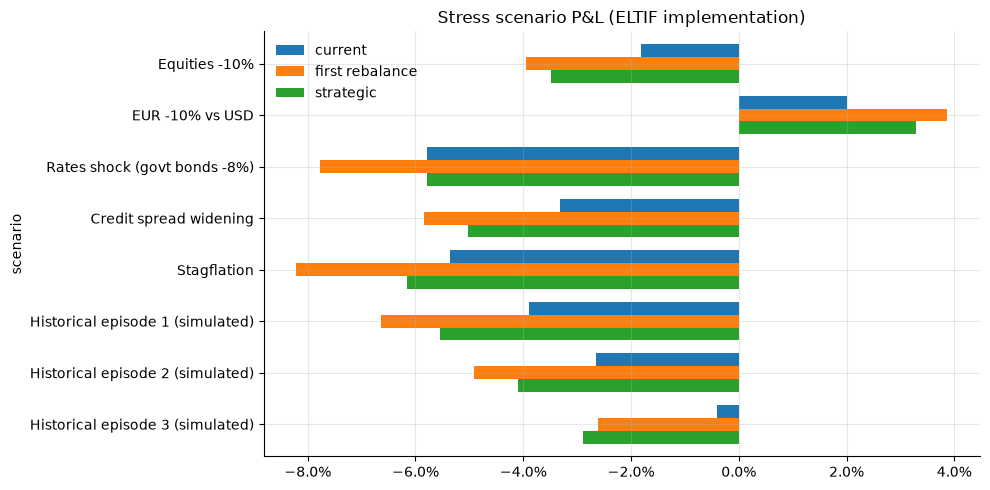

In [31]:
pf = {"current": w_cur, "first rebalance": W_path.iloc[0].values, "strategic": w_saa.values}
pnl, _ = fs.run(stress.scenario_shocks(data.stress_scenarios, data.stress_factors), pf)
display(pct(pnl, 1))
fig, ax = plt.subplots(figsize=(10, 5))
pnl.loc[~pnl.index.str.contains(r"\+")].plot.barh(ax=ax, width=0.75)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Stress scenario P&L (ELTIF implementation)")
ax.legend(frameon=False)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

### 11.2 Pro-forma performance on the (simulated) history

In [32]:
R = data.common_returns[u.names]
pro = performance_table(pd.DataFrame({p: R.values @ np.asarray(w) for p, w in pf.items()}, index=R.index))
pct(pro[["ann_return", "ann_vol", "max_drawdown", "var_95_monthly", "worst_month"]], 2).join(
    pro[["sharpe"]].round(2)
)

,ann_return,ann_vol,max_drawdown,var_95_monthly,worst_month,sharpe
current,4.89%,3.49%,-4.28%,1.05%,-2.96%,1.3900
first rebalance,5.93%,5.80%,-7.79%,2.19%,-4.83%,1.0200
strategic,6.45%,4.79%,-5.72%,1.66%,-3.90%,1.3300


### 11.3 Wealth projection along the transition path

5,000 paths, joint lognormal returns calibrated to the assumptions and the covariance. The weights
follow the quarterly transition path, then the last (strategic) weights.

,p5,p25,p50,p75,p95,p_beat_target,p_nominal_loss,p_real_loss
year,,,,,,,,
1,96.5,102.0,106.3,110.8,117.8,50%,15%,32%
3,101.2,111.9,120.2,129.2,143.1,51%,4%,20%
5,108.8,123.8,135.6,148.4,170.8,50%,1%,14%
10,134.9,161.6,183.6,209.1,251.2,50%,0%,6%


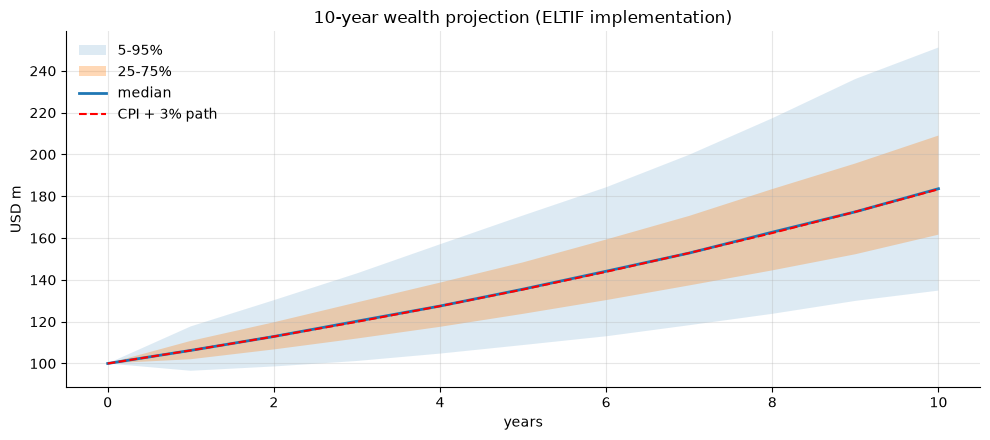

In [33]:
wp = simulate_wealth(
    u.mu,
    S.values,
    W_path,
    years=10,
    n_paths=5000,
    start_value=PV0,
    cpi=state.goals.cpi,
    target_return=goals.target_return,
    start=data.asof,
)
display(
    mio(wp.percentiles[["p5", "p25", "p50", "p75", "p95"]]).join(pct(wp.probabilities, 0)).loc[[1, 3, 5, 10]]
)
fig, ax = plt.subplots(figsize=(10, 4.5))
qq = wp.percentiles / 1e6
ax.fill_between(qq.index, qq["p5"], qq["p95"], alpha=0.15, label="5-95%")
ax.fill_between(qq.index, qq["p25"], qq["p75"], alpha=0.3, label="25-75%")
ax.plot(qq.index, qq["p50"], lw=2, label="median")
ax.plot(qq.index, PV0 / 1e6 * (1 + goals.target_return) ** qq.index, "r--", label="CPI + 3% path")
ax.set_xlabel("years")
ax.set_ylabel("USD m")
ax.set_title("10-year wealth projection (ELTIF implementation)")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

> **Fine print: stress and Monte Carlo.** Factor stress is linear (betas × shocks) and the Monte
> Carlo is lognormal with frozen assumptions, so crash probabilities are understated. Neither models
> a gate *closing*: a gate is a liquidity event, covered in section 10, not a valuation event. The
> goal test is geometric (compounded wealth against 1.0625^t).

## 12. Closed-end vs semi-liquid: side by side

The closed-end strategic allocation is re-solved here on the **same** data, goals and policy, with
the closed-end sleeves. The strategic target does not depend on the funding ladder, so none is
needed for this comparison. The transition, pacing and ladder figures for closed-end funds come
from the companion notebook.

In [34]:
assets_ce_policy = assets_ce.copy()
assets_ce_policy.loc[assets_ce_policy["name"] == "Priv Eq", "lb"] = PE_FLOOR
assets_ce_policy["ladder_bucket"] = (
    np.nan
)  # the strategic target needs no ladder (no calls are modelled here)
data_ce = build_mandate(
    assets_ce_policy,
    folder=os.path.join(tempfile.gettempdir(), "saa_pm_case_study_ce"),
    prices_df=prices_ce,
    groups_df=groups_ce,
    pacing_df=pacing_ce,
    holdings_df=holdings_ce,
)
state_ce = StateBuilder(data_ce).build()
res_ce = GoalOptimizer(state_ce.universe, state_ce.sigma, state_ce.optimizer).run()
w_ce = pd.Series(res_ce.weights, index=state_ce.universe.names)
cmp_saa = pd.DataFrame(
    {
        "closed-end SAA": dict(
            exp_return=res_ce.solution.exp_return,
            income=res_ce.solution.income,
            vol=res_ce.solution.vol,
            private=float(w_ce[list(VEHICLE)].sum()),
        ),
        "ELTIF SAA": stats(w_saa) | {"private": float(w_saa[PRIVATE].sum())},
    }
).T
cmp_saa = cmp_saa[["exp_return", "income", "vol", "private"]]
display(pct(cmp_saa, 2))
by_sleeve = pd.DataFrame(
    {"closed-end": w_ce[list(VEHICLE)].values, "ELTIF": w_saa[PRIVATE].values}, index=list(VEHICLE)
)
pct(by_sleeve, 1)

,exp_return,income,vol,private
closed-end SAA,6.70%,4.26%,6.00%,26.86%
ELTIF SAA,6.55%,4.00%,6.00%,30.09%


,closed-end,ELTIF
Priv Debt,14.0%,14.0%
Priv Eq,3.0%,3.0%
Priv Infra,9.9%,13.1%


In [35]:
vehicle_cmp = pd.DataFrame(
    {
        "closed-end funds (notebook 1)": {
            "strategic exp. return": f"{res_ce.solution.exp_return:.2%}",
            "strategic income": f"{res_ce.solution.income:.2%}",
            "time to strategic weights": "about 5 years (capital calls)",
            "goals first met": "first call date, 12 months in",
            "commitments, first 5 years": "about USD 48m, re-committed yearly",
            "funding ladder": "yes, net calls pre-funded",
            "J-curve": "yes, trough about USD 31m",
            "investor liquidity": "none until distributions",
            "main liquidity risk": "capital calls (cash out)",
            "fees": "management + carry",
        },
        "semi-liquid ELTIF (this notebook)": {
            "strategic exp. return": f"{cmp_saa.loc['ELTIF SAA', 'exp_return']:.2%}",
            "strategic income": f"{cmp_saa.loc['ELTIF SAA', 'income']:.2%}",
            "time to strategic weights": f"{int((path['turnover'] > 1e-3).sum())} quarterly rebalances",
            "goals first met": f"{first_met}",
            "commitments, first 5 years": "none (subscriptions at NAV)",
            "funding ladder": "not needed",
            "J-curve": "largely avoided (seasoned portfolio)",
            "investor liquidity": f"gated: {ELTIF_GATE:.0%} of holding per quarter in stress",
            "main liquidity risk": "gates (cash cannot get out)",
            "fees": f"higher: +{ELTIF_FEE:.1%} p.a., plus {ELTIF_CASH:.0%} cash drag",
        },
    }
)
vehicle_cmp

,closed-end funds (notebook 1),semi-liquid ELTIF (this notebook)
strategic exp. return,6.70%,6.55%
strategic income,4.26%,4.00%
time to strategic weights,about 5 years (capital calls),3 quarterly rebalances
goals first met,"first call date, 12 months in",2026-12
"commitments, first 5 years","about USD 48m, re-committed yearly",none (subscriptions at NAV)
funding ladder,"yes, net calls pre-funded",not needed
J-curve,"yes, trough about USD 31m",largely avoided (seasoned portfolio)
investor liquidity,none until distributions,gated: 5% of holding per quarter in stress
main liquidity risk,capital calls (cash out),gates (cash cannot get out)
fees,management + carry,"higher: +0.6% p.a., plus 15% cash drag"


**Interpretation:**

* **Return vs speed.** The ELTIF route gives up some strategic expected return (cash and fee drag)
  but reaches the target **years earlier**. Over the 5-year build-up of a closed-end programme, the
  liquid stand-in assets also earn less than private assets. The *realised* gap over the first years
  is therefore much smaller than the strategic gap.
* **Operational simplicity.** No pacing model, no recommitment decisions, no ladder, and no
  over- or under-commitment. For a USD 100m mandate without a private-markets team, that is a real
  advantage.
* **Liquidity is different, not better.** In normal times ELTIFs are more liquid. In a crisis the
  gate makes them almost as illiquid as closed-end funds, and the denominator effect hits harder,
  because nothing is "uncalled".
* **A hybrid is often best.** ELTIF for **private equity** (small tickets, diversification,
  no J-curve) and for the **ramp-up** of private debt. Closed-end funds for **senior direct lending
  and core infrastructure** once the scale justifies it, because the drag costs more there than it
  buys. Set e.g. `VEHICLE = {"Priv Debt": "closed_end", "Priv Eq": "eltif", "Priv Infra": "closed_end"}`
  in section 2c to see the hybrid strategic allocation. The closed-end sleeves then need the pacing
  plan and the ladder of the companion notebook.

## 13. Summary for the investment committee

In [36]:
summary = pd.DataFrame(
    {
        "current": stats(w_cur),
        "first rebalance": stats(W_path.iloc[0].values),
        "strategic target (ELTIF)": stats(w_saa),
    }
).T
summary["meets return goal"] = summary["exp_return"] >= goals.target_return - 1e-6
summary["meets income goal (3.5%)"] = summary["income"] >= 0.035 - 1e-6
summary["vol in 6-8% band"] = summary["vol"].between(goals.vol_lo - 1e-6, goals.vol_hi + 1e-6)
display(pct(summary[["exp_return", "income", "vol", "illiquid"]], 2).join(summary.iloc[:, 4:]))
n_rebalances = int((path["turnover"] > 1e-3).sum())
print(f"Goals first met at: {first_met} | rebalances to the strategic weights: {n_rebalances}")
print(
    f"P(10y annualised return >= CPI+3%): {wp.probabilities.loc[10, 'p_beat_target']:.0%} | "
    f"P(real loss after 10y): {wp.probabilities.loc[10, 'p_real_loss']:.0%}"
)

,exp_return,income,vol,illiquid,meets return goal,meets income goal (3.5%),vol in 6-8% band
current,4.97%,3.46%,3.34%,0.00%,False,False,False
first rebalance,6.11%,3.41%,6.50%,7.32%,False,False,True
strategic target (ELTIF),6.55%,4.00%,6.00%,30.09%,True,True,True


Goals first met at: 2026-12 | rebalances to the strategic weights: 3
P(10y annualised return >= CPI+3%): 50% | P(real loss after 10y): 6%


### Recommendations

1. **Client profile.** As in the closed-end case. In addition, confirm the client's tolerance for
   **gated** liquidity and the share-class choice (distributing, for the income goal).
2. **Strategic allocation.** The same goal-ordered SAA, with the private sleeves held through ELTIFs
   (the "illiquid" column above is the ELTIF share). It meets CPI + 3% and the income goal at the
   bottom of the 6–8% band.
3. **Transition.** Rotate out of cash and build the ELTIF sleeves within the first rebalances (the
   turnover cap sets the speed; tranches for equities). There is no pacing plan and no funding
   ladder.
4. **Implementation.** Select 2–3 ELTIFs per sleeve whose portfolios match the target sub-strategy
   mix: senior direct lending, a secondaries-led PE fund, core and core-plus infrastructure.
5. **Liquidity.** Private Markets ≤ 32%, with a lower strategic target or an explicit buffer policy
   (section 10.4). At least 60% fully liquid. Gate-aware rebalancing. Due diligence on liquidity sleeves and gate mechanics.
6. **Vehicle decision.** Weigh the **return drag** (section 12) against **speed and simplicity**.
   Consider a hybrid: ELTIF for PE and the ramp-up, closed-end for core private debt and
   infrastructure as the programme scales.
7. **Data governance.** Run `data_check.py` on every data delivery. No FAIL may remain, and every
   WARN needs an explanation.

---

*All data in this notebook is simulated, and the ELTIF parameters (cash sleeve, extra fee, gate)
are illustrative. The results illustrate the method and say nothing about real funds or markets.
For research and educational use; not investment advice.*